# Maximum cut

## Problem description

Consider an undirected graph $G = (V, E)$ (assume $|V| = n$) with weights on the edges in $E$. The goal of the Max-Cut problem is to find a cut (partition nodes into $S$ and $V\setminus S$) so that the sum of the weights of the cut edges is maximised.

## Problem formulation 1

The model variables are the following:
* $v_i \in \{0,1\}$: Binary variable indicating if vertex $i$ is in $S$.

The objective is:

$\max f(v) = \sum_{(i,j)\in E} w_{ij} |v_i - v_j|$,

where $w_{ij}$ is the weight of the edge connecting node $i$ with node $j$.

## Problem formulation 2

The model variables are the following:
* $v_i \in \{-1,1\}$: Integer variable indicating if vertex $i$ is in $S$ ($v_i = 1$) or not ($v_i = -1$).

The objective is:

$\max f(v) = \frac{1}{4}\sum_{i = 1}^n \sum_{j = 1}^n w_{ij} (1 - v_i\cdot v_j)$,

where $w_{ij}$ is the weight of the edge connecting node $i$ with node $j$.

We can relax the domain of the variables to be continuous and impose the following constraints:

$v_i^2 = 1, \quad \forall i \in \{1, \dots, n\}.$

## Required packages

In [1]:
import random
import gurobipy as gp
import networkx as nx
from itertools import combinations
import matplotlib.pyplot as plt
import cvxpy as cp
import numpy as np
import scipy as sp
import cvxopt # needs installed for optimization

## Data generation

The following code generates random connected graph. The value for `number_of_nodes`, `edge_density` and `max_edge_weight` can be changed.

In [2]:
# The values for the graph
number_of_nodes = 10
edge_density = 0.5      # Should be in [0,1]
max_edge_weight = 10
random.seed(2026)

# Correcting edge_density if not in [0,1]
edge_density = max(min(edge_density, 1), 1/number_of_nodes)
# Creating edge weight options
edge_weights = [i for i in range(1,max(1,max_edge_weight))]

# Generating nodes of graph
G = nx.Graph()
for i in range(number_of_nodes):
    G.add_node(i)

# Creating set of all connections
edge_set = set(combinations(range(number_of_nodes), 2))

# Connecting all nodes (unconnected components are boring)
for i in range(number_of_nodes-1):
    G.add_edge(i, i+1, weight=random.choice(edge_weights))
    edge_set.remove((i,i+1))

# Randomly choose edges to add until density reached
while True:
    edge = random.choice(list(edge_set))
    G.add_edge(edge[0],edge[1], weight=random.choice(edge_weights))
    edge_set.remove(edge)
    if nx.density(G) > edge_density:
        break

The following code provides a preview of the graph.

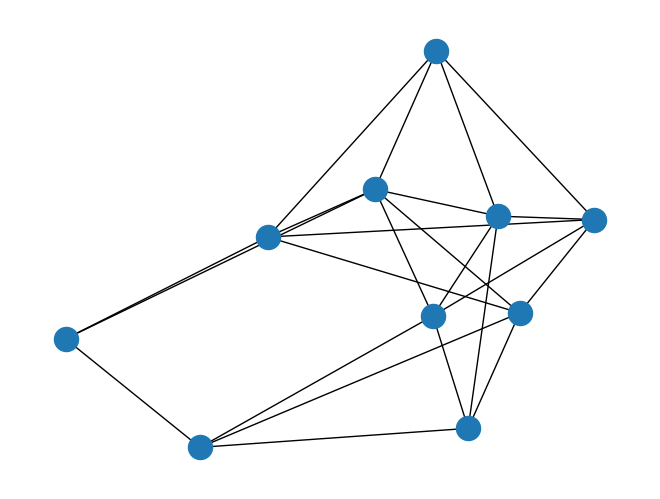

In [3]:
pos = nx.spring_layout(G)
nx.draw(G, pos)

## Model building and solving (Formulation 1)

The following code builds and solves the first model formulation using the Gurobi API for Python.

In [4]:
# Initialise model
model = gp.Model()

# Add variables
v = model.addVars(number_of_nodes, name="v", vtype="b")
e = {}
e_plus = {}

# Constraints and objective
objective_function = gp.LinExpr()
for i, edge in enumerate(G.edges):
    e[i] = model.addVar(name=f"e_{edge[0]}_{edge[1]}", lb = -float('inf'))
    e_plus[i] = model.addVar(name=f"e_{edge[0]}_{edge[1]}", lb = -float('inf'))
    model.addConstr(e[i] == v[edge[0]] - v[edge[1]])
    model.addConstr(e_plus[i] == gp.abs_(e[i]))
    objective_function.add(G.get_edge_data(edge[0],edge[1])["weight"]*e_plus[i])

# Set objective function
model.setObjective(objective_function, gp.GRB.MAXIMIZE)

# Optimize model
model.optimize()

Set parameter Username
Set parameter LicenseID to value 2751469
Academic license - for non-commercial use only - expires 2026-12-08
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 11th Gen Intel(R) Core(TM) i7-1165G7 @ 2.80GHz, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 23 rows, 56 columns and 69 nonzeros (Max)
Model fingerprint: 0xfc1a8b19
Model has 23 linear objective coefficients
Model has 23 simple general constraints
  23 ABS
Variable types: 46 continuous, 10 integer (10 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 9e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [0e+00, 0e+00]

Found heuristic solution: objective -0.0000000
Presolve added 69 rows and 46 columns
Presolve time: 0.00s
Presolved: 92 rows, 102 columns, 276 nonzeros
Variable types: 69 continuous, 33 integer (33 binary)

R

## Solution handling

The following code collects and prints the solution.

In [5]:
# Collecting the partition
S_set = set()
not_S_set = set()
for i in range(number_of_nodes):
    if v[i].X == 1:
        S_set.add(i)
    else:
        not_S_set.add(i)
print(f"S: {S_set}")
print(f"V minus S: {not_S_set}")

# Collecting the cut edges
cut_edges = set()
for edge in e_plus:
    variable = e_plus[edge]
    if variable.X == 1:
        v1 = int(variable.VarName.split("_")[1])
        v2 = int(variable.VarName.split("_")[2])
        cut_edges.add((v1,v2))
print(f"Cut edges: {cut_edges}")

# Collect optimal solution
solution_value_optimal = model.ObjVal
print(f"Objective value: {solution_value_optimal}")

S: {8, 1, 3, 6}
V minus S: {0, 2, 4, 5, 7, 9}
Cut edges: {(0, 1), (1, 2), (3, 4), (5, 8), (4, 6), (0, 6), (2, 3), (6, 7), (1, 7), (8, 9), (5, 6), (4, 8), (0, 8), (6, 9), (1, 9), (7, 8)}
Objective value: 109.0


The following code plots the graph from above colouring the nodes into the partition. Cut edges are highlighted.

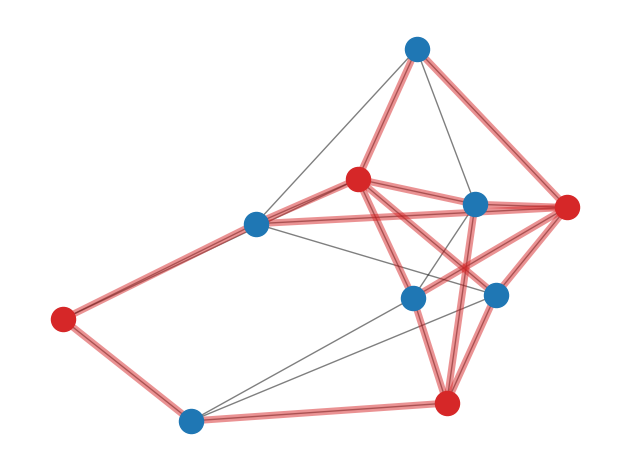

In [6]:
# Nodes
nx.draw_networkx_nodes(G, pos, nodelist=list(S_set), node_color="tab:red")
nx.draw_networkx_nodes(G, pos, nodelist=list(not_S_set), node_color="tab:blue")

# Edges
nx.draw_networkx_edges(G, pos, width=1.0, alpha=0.5)
nx.draw_networkx_edges(G, pos, edgelist=list(cut_edges), width=5, alpha=0.5, edge_color="tab:red")

# Plot figure
plt.tight_layout()
plt.axis("off")
plt.show()

## Model building and solving (Formulation 2)

The following code builds and solves the second model formulation using the Gurobi API for Python.

In [8]:
# Initialise model
model = gp.Model()

# Add variables
v = model.addVars(number_of_nodes, name="v", vtype="c", lb = -float('inf'))
e = {}

# Constraints
model.addConstrs(v[i]*v[i] == 1 for i in range(number_of_nodes))
objective_function = gp.LinExpr()
for i, edge in enumerate(G.edges):
    e[i] = model.addVar(name=f"e_{edge[0]}_{edge[1]}", lb = -float('inf'))
    model.addConstr(e[i] == 1 - v[edge[0]]*v[edge[1]])
    objective_function.add(G.get_edge_data(edge[0],edge[1])["weight"]*e[i])

# Add objective function
# (Note a slight change in scaling due to not double counting edges)
model.setObjective(0.5*objective_function, gp.GRB.MAXIMIZE)

# Optimize model
model.optimize()

Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: 11th Gen Intel(R) Core(TM) i7-1165G7 @ 2.80GHz, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 0 rows, 33 columns and 0 nonzeros (Max)
Model fingerprint: 0x6753e4ac
Model has 23 linear objective coefficients
Model has 33 quadratic constraints
Coefficient statistics:
  Matrix range     [0e+00, 0e+00]
  QMatrix range    [1e+00, 1e+00]
  QLMatrix range   [1e+00, 1e+00]
  Objective range  [5e-01, 5e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [0e+00, 0e+00]
  QRHS range       [1e+00, 1e+00]


Continuous model is non-convex -- solving as a MIP


Presolve removed 0 rows and 24 columns
Presolve time: 0.00s
Presolved: 16 rows, 25 columns, 48 nonzeros
Variable types: 0 continuous, 25 integer (25 binary)
Found heuristic solution: objective 56.0000000
Found heuristic solution: objective 74.0000000

Ro

## Solution handling

The following code collects and prints the solution.

In [9]:
# Collecting the partition
S_set = set()
not_S_set = set()
for i in range(number_of_nodes):
    if v[i].X == 1:
        S_set.add(i)
    else:
        not_S_set.add(i)
print(f"S: {S_set}")
print(f"V minus S: {not_S_set}")

# Collecting the cut edges
cut_edges = set()
for edge in e:
    variable = e[edge]
    if variable.X != 0:
        v1 = int(variable.VarName.split("_")[1])
        v2 = int(variable.VarName.split("_")[2])
        cut_edges.add((v1,v2))
print(f"Cut edges: {cut_edges}")

# Collect optimal solution
solution_value_optimal_2 = model.ObjVal
print(f"Objective value 1: {solution_value_optimal}")
print(f"Objective value 2: {solution_value_optimal_2}")

S: {0, 2, 4, 5, 7, 9}
V minus S: {8, 1, 3, 6}
Cut edges: {(0, 1), (1, 2), (3, 4), (5, 8), (4, 6), (0, 6), (2, 3), (6, 7), (1, 7), (8, 9), (5, 6), (4, 8), (0, 8), (6, 9), (1, 9), (7, 8)}
Objective value 1: 109.0
Objective value 2: 109.0


The following code plots the graph from above colouring the nodes into the partition. Cut edges are highlighted.

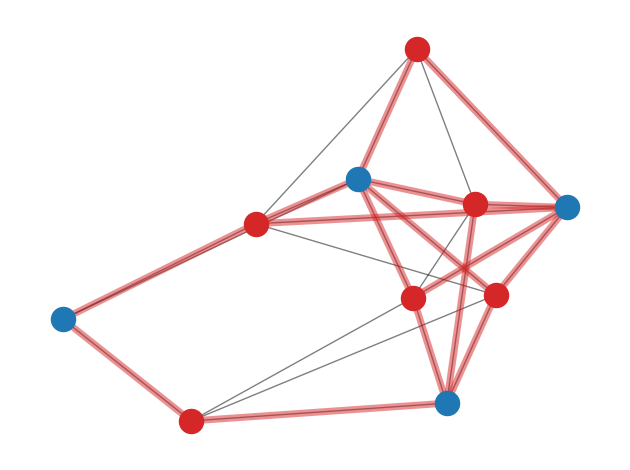

In [10]:
# Nodes
nx.draw_networkx_nodes(G, pos, nodelist=list(S_set), node_color="tab:red")
nx.draw_networkx_nodes(G, pos, nodelist=list(not_S_set), node_color="tab:blue")

# Edges
nx.draw_networkx_edges(G, pos, width=1.0, alpha=0.5)
nx.draw_networkx_edges(G, pos, edgelist=list(cut_edges), width=5, alpha=0.5, edge_color="tab:red")

# Plot figure
plt.tight_layout()
plt.axis("off")
plt.show()

# Semidefinite relaxation

The SDP relation of the maximum cut problem looks as follows:

$\max f(v) = \frac{1}{4}\sum_{i = 1}^n \sum_{j = 1}^n w_{ij} (1 - \overline{\underline{X}}_{ij})$,

where $w_{ij}$ is the weight of the edge connecting node $i$ with node $j$.

Subject to:

$\overline{\underline{X}} \in S_+^n,$

$\overline{\underline{X}}_{ii} = 1, \quad \forall i \in \{1, \dots, n\}.$

## Model building and solving SDP

The following code builds and solves the approximation approach using CVXPY. SDPs are not currently supported by Gurobi.

In [11]:
# Adding matrix of variables (PSD = positive semi-definite)
X = cp.Variable((number_of_nodes,number_of_nodes), PSD=True)

# Set up the constraints
constraints = [X[i,i] == 1 for i in range(number_of_nodes)]

# Set up objective
objective = 0
for i, edge in enumerate(G.edges):
    weight = G.get_edge_data(edge[0],edge[1])["weight"]
    objective += weight*(1 - X[edge[0],edge[1]]) + weight*(1 - X[edge[1],edge[0]])

# Set and solve problem
problem = cp.Problem(cp.Maximize(0.25*objective),
                  constraints)
problem.solve(solver = 'CVXOPT')

# Print result
print("The optimal value is", problem.value)
print()
print("Eigenvalues: ",np.linalg.eigvalsh(X.value))


The optimal value is 109.02948567613684

Eigenvalues:  [5.65254905e-10 2.24158831e-09 5.13579813e-09 5.64581001e-09
 7.01823931e-09 1.15351127e-08 3.56107294e-08 8.35948946e-08
 4.30282633e-01 9.56971722e+00]


## Solver discussion

As you can see, we have switched to using CVXPY and the CVXOPT package. Try different solvers (use following code to see what is installed) and see what happens. Do any problems arise?

In [14]:
cp.installed_solvers()

['CLARABEL',
 'CVXOPT',
 'GLPK',
 'GLPK_MI',
 'GUROBI',
 'HIGHS',
 'OSQP',
 'SCIPY',
 'SCS']

## Decomposition and approximation

The following code finds the cholesky factorisation and extracts the rows of the factorisation. We sample a random unit vector and produce a solution for the cut problem.

In [12]:
# Get the cholesky factorisation
cholesky_factorisation = np.linalg.cholesky(X.value)
print("Factorization (approx)")
print(cholesky_factorisation.round(3))

# Extract the rows
N_v = {}
for i in range(number_of_nodes):
    N_v[i] = cholesky_factorisation[i]

# Generate a unit sphere and sample from it
uniform_sphere_dist = sp.stats.uniform_direction(dim = number_of_nodes)
unit_vector = uniform_sphere_dist.rvs(1)[0]
print()
print("Chosen unit vector")
print(unit_vector)

# Generating the cut
S_set = set()
not_S_set = set()
for i in range(number_of_nodes):
    inner_product = np.inner(N_v[i],unit_vector)
    if inner_product >= 0:
        S_set.add(i)
    else:
        not_S_set.add(i)
print()
print(f"S: {S_set}")
print(f"V minus S: {not_S_set}")

# Getting cut edges and the final solution value
cut_edges = set()
solution_value = 0
for edge in G.edges:
    # Both in S
    if edge[0] in S_set and edge[1] in S_set:
        continue
    # Both not in S
    if edge[0] in not_S_set and edge[1] in not_S_set:
        continue
    # In different sets
    cut_edges.add(edge)
    solution_value += G.get_edge_data(edge[0],edge[1])["weight"]
print(f"Cut edges: {cut_edges}")
print(f"Solution value: {solution_value}")

Factorization (approx)
[[ 1.     0.     0.     0.     0.     0.     0.     0.     0.     0.   ]
 [-0.928  0.372  0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.978 -0.21   0.     0.     0.     0.     0.     0.     0.     0.   ]
 [-0.982  0.189 -0.     0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.983 -0.185  0.    -0.     0.     0.     0.     0.     0.     0.   ]
 [ 0.708 -0.706 -0.     0.    -0.     0.     0.     0.     0.     0.   ]
 [-0.941  0.338  0.    -0.     0.    -0.     0.     0.     0.     0.   ]
 [ 0.906 -0.424 -0.     0.    -0.     0.    -0.     0.     0.     0.   ]
 [-0.939  0.344  0.     0.     0.    -0.     0.     0.     0.     0.   ]
 [ 0.831 -0.556 -0.    -0.     0.     0.    -0.     0.    -0.     0.   ]]

Chosen unit vector
[-0.39611072 -0.1194055  -0.4223472   0.41746436 -0.41280435 -0.27887614
  0.38761601 -0.21305701  0.17976888 -0.0070235 ]

S: {8, 1, 3, 6}
V minus S: {0, 2, 4, 5, 7, 9}
Cut edges: {(0, 1), (1, 2), (3, 4), (5, 8), (4, 6), (0, 

## Sampling many vectors

Repeat this $k$ times and find average solution value. We compare with the solution values from earlier.

In [17]:
# Sample vectors
k = 100

# Generate a unit sphere and sample from it
uniform_sphere_dist = sp.stats.uniform_direction(dim = number_of_nodes)
unit_vectors = uniform_sphere_dist.rvs(k)

# Repeat above process
all_solution_values = []
for i in range(k):
    # Get vector
    unit_vector = unit_vectors[i]
    
    # Generate the cut
    S_set = set()
    not_S_set = set()
    for i in range(number_of_nodes):
        inner_product = np.inner(N_v[i],unit_vector)
        if inner_product >= 0:
            S_set.add(i)
        else:
            not_S_set.add(i)

    # Get solution value
    solution_value = 0
    for edge in G.edges:
        # Both in S
        if edge[0] in S_set and edge[1] in S_set:
            continue
        # Both not in S
        if edge[0] in not_S_set and edge[1] in not_S_set:
            continue
        # In different sets
        solution_value += G.get_edge_data(edge[0],edge[1])["weight"]

    # Append to solution values
    all_solution_values.append(solution_value)

# Calculate average solution value
average_solution_value = sum(all_solution_values)/len(all_solution_values)
print(f"Average solution value: {average_solution_value}")
print(f"Best solution found: {max(all_solution_values)}")
print(f"Optimal solution value: {solution_value_optimal}")
print(f"Ratio: {average_solution_value/solution_value_optimal} ({k} samples)")

Average solution value: 105.56
Best solution found: 109
Optimal solution value: 109.0
Ratio: 0.968440366972477 (100 samples)
